<div style="display: flex; align-items: center;">
    <img src="https://raw.githubusercontent.com/ilastik/marching_cubes/master/test/image.png" alt="Image Alt Text" width="200" height="200" style="margin-right: 20px;">
    <div style="font-size: 60px;">
         <strong> 6<sup>th</sup> lab <strong>
    <div style="font-size: 40px;margin-right: 30px">
         <strong> Surfaces : extraction and meshes <strong>
    </div>
</div>

<table>
  <tr>
    <td style="background-color: rgba(114, 147, 203, 0.9); font-size: 15px; color: white; padding: 20px;">
      <div style="font-size: 20px"> 
          <strong>XCT Module (2 x 2h)</strong><br>
      </div>  
      <ul>
        <li> <strong> Week 1 : visualisation and using of ready-to-use functions</strong> (2h)</li>
        <ul>
           <li> discover scikit image libary for XCT 
           <li> read files
           <li> plot profiles and global criteria
           <li> projections, sinograms
           <li> reconstruction with library functions (inverse Radon, FBP, SART)
        </ul>
        <br> 
        <li> <strong> Week 2 : code writing and analyses</strong> (2h)</li>
        <ul>
           <li> SART reconstruction code
           <li> FBP coding
           <li> compare with ready-to-use functions
           <li> use of global and local metrics to compare the results
        </ul>
    </td>
    <td style="background-color: rgba(225, 151, 76, 0.7); font-size: 15px; color: white; padding: 20px; vertical-align: top;">
    <div style="font-size: 20px"> 
        <strong> MRI Module (2 x 2h)</strong><br>
    </div> 
    <ul>
        <li> <strong> Week 3 : visualisation and using of ready-to-use functions</strong> (2h)</li>
        <ul>
           <li> discover scikit image libary for MRI
           <li> read files
           <li> K-space coding
        </ul>
        <br> 
        <li> <strong> Week 4 : analyses and interpretations </strong> (2h)</li>
    </td>
    <td style="background-color: rgba(132, 186, 91, 0.8); font-size: 15px; color: white; padding: 20px; vertical-align: top;">
    <div style="font-size: 20px"> 
      <strong> Numerisation Module (2 x 2h)</strong><br>
    </div> 
      <ul>
        <li> <strong> Week 5 : depth map exploration </strong> (2h)</li>
        <br> 
        <li> <strong> Week 6 : point cloud and mesh understanding</strong> (2h)</li>
    </td>
  </tr>
</table>


<div style="display: flex; align-items: center;">
    <img src="https://img.freepik.com/premium-vector/warning-signs-high-voltage-hazard-isolated-white-background_68708-427.jpg?w=2000" alt="Image Alt Text" width="50" height="50" style="margin-right: 20px;">
    <div style="font-size: 15px;margin-right: 30px">
            Each lab must be completed before the beginning of the other lab session. 
        <br> 
          <strong>Don't forget to title your .ipynb file with your name and surname. <strong>
        <br> 
         The final submission of the last module has to be done <strong> after holidays on the 7<sup>th</sup>November before 6 pm</strong>
    </div>
</div>

<table>
      <td style="border-left: 3px solid rgba(114, 147, 203, 0.9); background-color: rgba(114, 147, 203, 0.1); font-size: 15px; color: blakc; padding-left: 30px;">
        Don't forget to legend your figures and graphs. Interpretations are expected and must by short but comprehensive.  
      </td>
</table>

#### Contact : meghna.parameswaran-ayyar@u-bordeaux.fr

<div style="display: flex; align-items: center;">
    <img src="https://upload.wikimedia.org/wikipedia/commons/f/fb/Dolphin_triangle_mesh.png" alt="Image Alt Text" width="300" height="300" style="margin-right: 20px;">
    <div style="font-size: 30px;">
         <strong> Part 1<strong>
    <div style="font-size: 20px;margin-right: 30px">
         <strong> From PGM3D to mesh <strong>
    </div>
</div>

PGM3D is a semi-standard file format for the extension in 3D of the popular PGM (Portable GreyMap) format. It is very simple, being only a text file with a header containing basic information and the values of the voxels. 
Example of a PGM3D syntax :

PGM3D # Identifier
512 512 512 # Size 
45
154
56
.... # values of voxels

Values of voxels are separated by a space, a tabulation or a return. There are unformatted meaning that they can be on a single, a single column (as the example above), etc.


The goal of this part is to extract surfaces **between** area of different graylevels. These surfaces will be composed of squared faces that are the shared faces between two voxels of different intensities.
The algorithm is then very simple : for each voxel, check if its neighbors have a different intensity and, if so, create a face in the mesh corresponding to the shared face between this two voxels. To optimize this mesh for GPUs, the square face has to be cut in two triangle faces (beware of the order of the vertices to ensure the correct normal orientation - counter clockwise).

### Visualize data

- Let's start with reading the text file efficiently and loading the voxels into an array that we can traverse easily for the surface extraction part. We will use the file 'shepplogan.pgm3d' given with this Lab.
- You will extract the __extension__, the __size__ and finally the __data__
- Display the 3D volume in its 3 views you can choose any 3 slices to do this

Extension : PGM3D
Size (x, y, z) : (64, 64, 64)
Array shape (z, y, x) : (64, 64, 64) | type : int32
gray level   0 : 195143 voxels
gray level  25 :     29 voxels
gray level  51 :  55490 voxels
gray level  76 :   2954 voxels
gray level 102 :      5 voxels
gray level 255 :   8523 voxels


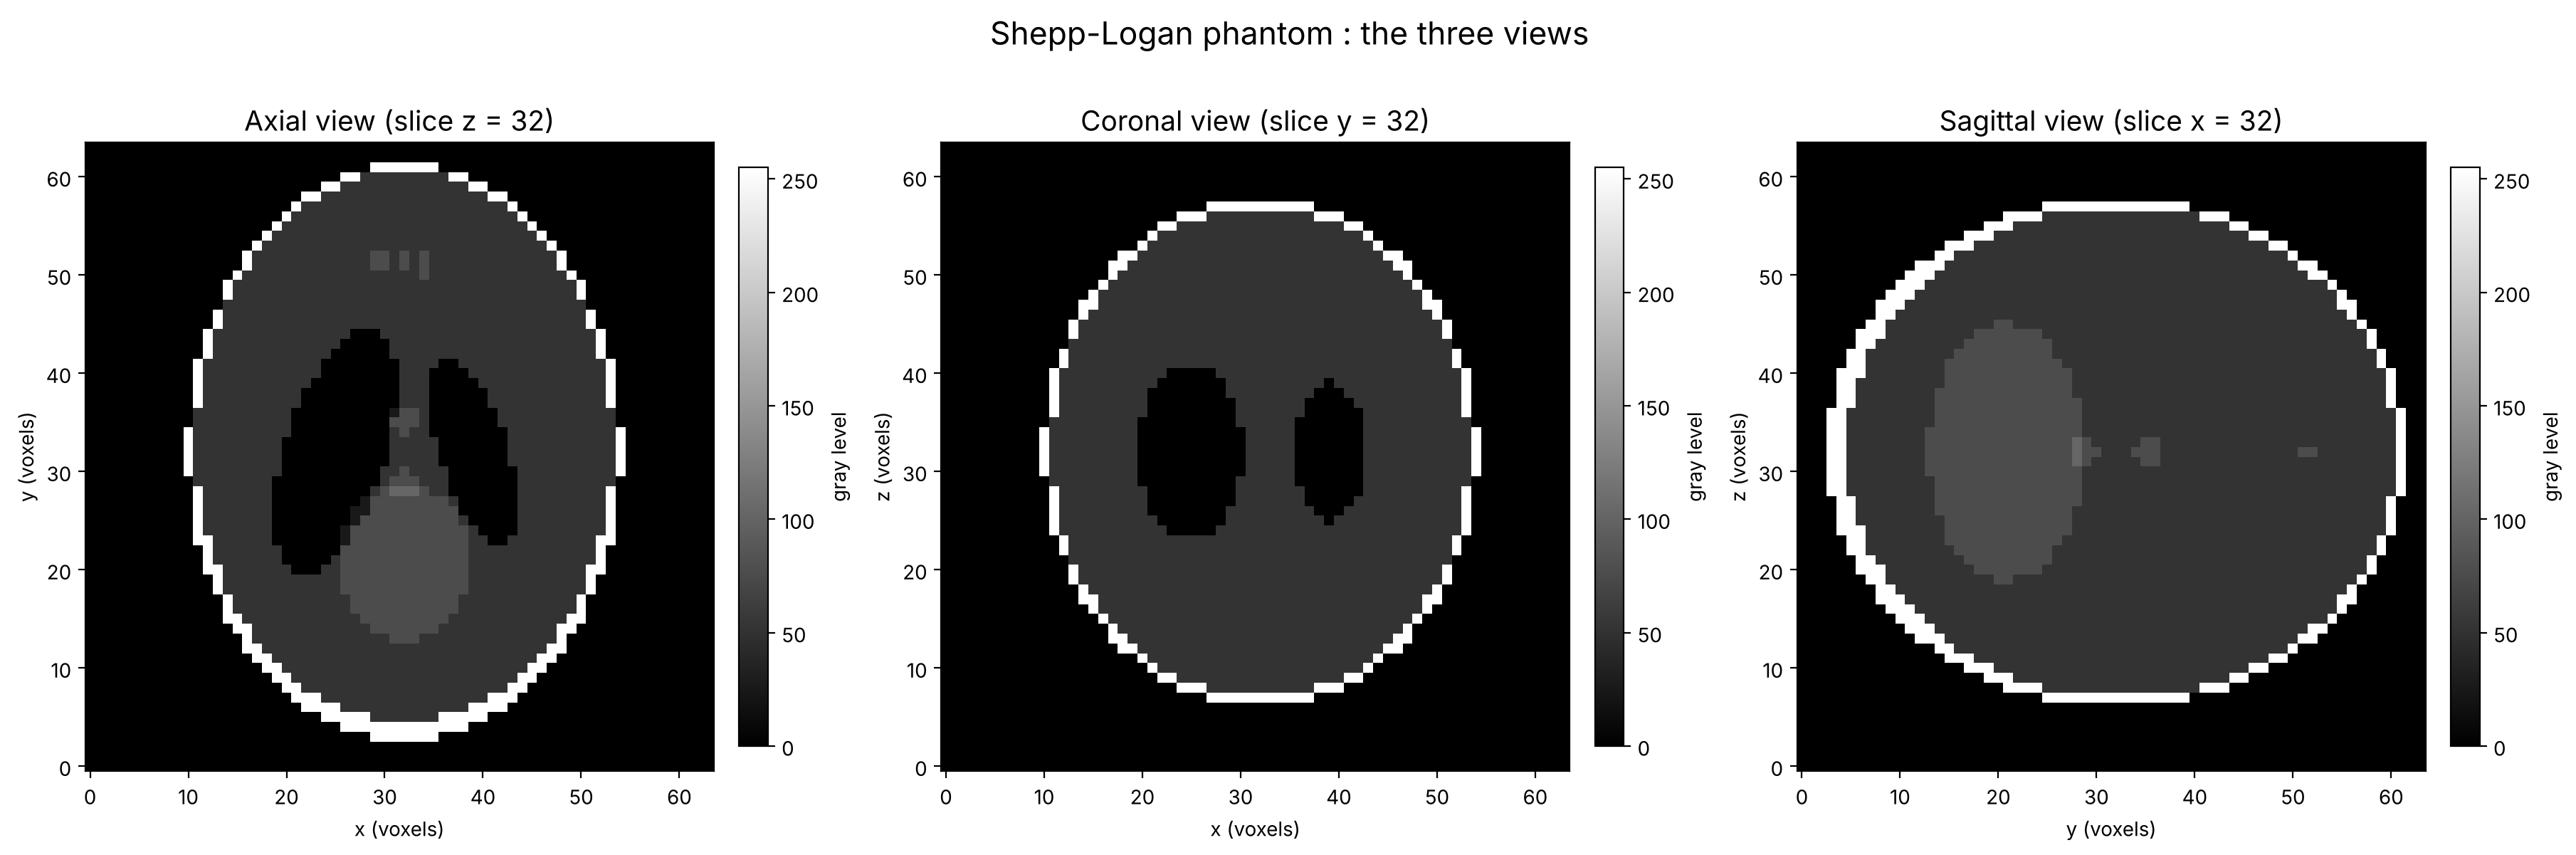

In [ ]:

import re
import numpy as np
import matplotlib.pyplot as plt


def read_pgm3d(filename):
    """Read a PGM3D text file and return its extension (identifier), its size and the voxels as a 3D array."""
    with open(filename, "r") as f:
        text = f.read()
    text = re.sub(r"#.*", "", text)        # remove the comments (everything after a '#')
    tokens = text.split()                  # values can be separated by spaces, tabulations or line breaks
    extension = tokens[0]
    size = tuple(int(t) for t in tokens[1:4])          # (width, height, depth) = (x, y, z)
    data = np.array(tokens[4:], dtype=np.int32)
    if data.size != size[0] * size[1] * size[2]:
        raise ValueError("The number of voxels does not match the size written in the header")
    # in the file x varies the fastest, then y, then z : the array is indexed as volume[z, y, x]
    volume = data.reshape(size[2], size[1], size[0])
    return extension, size, volume


extension, size, volume = read_pgm3d("shepplogan.pgm3d")
print("Extension :", extension)
print("Size (x, y, z) :", size)
print("Array shape (z, y, x) :", volume.shape, "| type :", volume.dtype)
gray_levels, counts = np.unique(volume, return_counts=True)
for g, c in zip(gray_levels, counts):
    print(f"gray level {g:3d} : {c:6d} voxels")

# three views through the middle of the volume
sx, sy, sz = size[0] // 2, size[1] // 2, size[2] // 2
views = [
    (volume[sz, :, :], f"Axial view (slice z = {sz})", "x (voxels)", "y (voxels)"),
    (volume[:, sy, :], f"Coronal view (slice y = {sy})", "x (voxels)", "z (voxels)"),
    (volume[:, :, sx], f"Sagittal view (slice x = {sx})", "y (voxels)", "z (voxels)"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
for ax, (image, title, xlabel, ylabel) in zip(axes, views):
    im = ax.imshow(image, cmap="gray", vmin=0, vmax=255, origin="lower")
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="gray level")
fig.suptitle("Shepp-Logan phantom : the three views", fontsize=16)
plt.show()



The file starts with the extension `PGM3D`, then the size `64 64 64`, then 64 x 64 x 64 = 262 144 voxel values, one per line. To read it, I remove the possible comments (everything after a `#`), split the text on any white space, take the first token as the extension, the next three as the size and convert the rest to integers. The values are then reshaped so that the array is indexed as `volume[z, y, x]`, because in the file x changes the fastest, then y, then z. The number of values is checked against the size of the header.

The phantom contains six gray levels: 0 (empty space around the head and inside the two dark cavities), 25 and 102 (only a few voxels), 51 (the soft tissue, 55 490 voxels), 76 (a lighter ellipsoid, 2 954 voxels) and 255 (the bright outer shell, 8 523 voxels).

On the three views (taken in the middle of the volume):
- the axial view shows the bright shell around gray tissue, two large dark cavities, a lighter region (gray level 76) below them and a few small bright spots at the top;
- the coronal view cuts the two cavities as two dark ellipses of different size;
- the sagittal view shows the lighter ellipsoid (gray level 76) in the left part and a few small spots on its right.

The regions are flat areas with sharp jumps of gray level, with no smooth transition. This is why a surface between two regions can be found just by comparing the intensity of neighbouring voxels.

### Create a mesh

- Now, let's create a list of vertices and a list of faces and append these information when we find a face between two voxels of different intensities.
- You will write a code of nested loops that iterate over a 3D array to identify boundaries or surfaces between regions labeled with different values. These boundaries are represented as vertices and faces and will be stored in the __verticeList__ and __faceList__ lists.   

Before you begin the code have a look at the section that gives an example of the .obj file to be created to be clear what kind of vertice and face list you need to make in this code to be able to save it in the correct format and then use a visualizer to display it

In [ ]:


# The 6 neighbours of a voxel. For each one : the offset (dx, dy, dz) towards the neighbour and the 4 corners of the
# square face shared with it. Corners are given in voxel-corner coordinates (voxel (x, y, z) is the cube
# [x, x+1] x [y, y+1] x [z, z+1]) and are ordered counter-clockwise when the face is seen from outside of the voxel,
# so that the normal of the face points away from the voxel.
neighbours = [
    ((+1, 0, 0), [(1, 0, 0), (1, 1, 0), (1, 1, 1), (1, 0, 1)]),   # neighbour in +x
    ((-1, 0, 0), [(0, 0, 0), (0, 0, 1), (0, 1, 1), (0, 1, 0)]),   # neighbour in -x
    ((0, +1, 0), [(0, 1, 0), (0, 1, 1), (1, 1, 1), (1, 1, 0)]),   # neighbour in +y
    ((0, -1, 0), [(0, 0, 0), (1, 0, 0), (1, 0, 1), (0, 0, 1)]),   # neighbour in -y
    ((0, 0, +1), [(0, 0, 1), (1, 0, 1), (1, 1, 1), (0, 1, 1)]),   # neighbour in +z
    ((0, 0, -1), [(0, 0, 0), (0, 1, 0), (1, 1, 0), (1, 0, 0)]),   # neighbour in -z
]


def extract_surface(volume, gray_level):
    """Faces between the voxels of intensity gray_level and their neighbours of a different intensity.
    Returns verticeList (list of (x, y, z)) and faceList (list of triangles (i, j, k)).
    Indices in faceList start at 1, as in a .obj file."""
    nz, ny, nx = volume.shape
    verticeList = []
    faceList = []
    index_of = {}      # coordinates of a vertex -> its index, so that a corner shared by several faces is stored only once

    def get_index(vertex):
        if vertex not in index_of:
            verticeList.append(vertex)
            index_of[vertex] = len(verticeList)          # the first vertex has the index 1
        return index_of[vertex]

    for z in range(nz):
        for y in range(ny):
            for x in range(nx):
                if volume[z, y, x] != gray_level:
                    continue
                for (dx, dy, dz), corners in neighbours:
                    xn, yn, zn = x + dx, y + dy, z + dz
                    if not (0 <= xn < nx and 0 <= yn < ny and 0 <= zn < nz):
                        continue                         # outside of the volume : no neighbour, so no face
                    if volume[zn, yn, xn] == gray_level:
                        continue                         # same intensity : no surface here
                    v1, v2, v3, v4 = [get_index((x + cx, y + cy, z + cz)) for cx, cy, cz in corners]
                    faceList.append((v1, v2, v3))        # the square face is cut into two triangles
                    faceList.append((v1, v3, v4))
    return verticeList, faceList


# one surface for each object (gray level 0 is the empty space around the head and inside the cavities)
object_levels = [int(g) for g in gray_levels if g != 0]
surfaces = {g: extract_surface(volume, g) for g in object_levels}

print("gray level | voxels | vertices | triangles")
for g, (vertices, faces) in surfaces.items():
    print(f"{g:10d} | {np.count_nonzero(volume == g):6d} | {len(vertices):8d} | {len(faces):9d}")

# the surface used in the next steps : the outer shell
label = 255
verticeList, faceList = surfaces[label]

gray level | voxels | vertices | triangles
        25 |     29 |      102 |       212
        51 |  55490 |    15192 |     30416
        76 |   2954 |     1676 |      3344
       102 |      5 |       24 |        44
       255 |   8523 |    20212 |     46912


In [ ]:

# Check of the orientation of the faces. If every normal points outwards, the volume enclosed by the surface is
# V = 1/6 * sum over all triangles of dot(v1, cross(v2, v3))
# with v1, v2, v3 the three vertices of a triangle, cross the cross product and dot the dot product.
# It must be equal to the number of voxels of the object (a reversed face would make it smaller).
def enclosed_volume(vertices, faces):
    v = np.array(vertices, dtype=float)
    f = np.array(faces) - 1                      # indices start at 0 in a numpy array
    a, b, c = v[f[:, 0]], v[f[:, 1]], v[f[:, 2]]
    return np.sum(np.einsum("ij,ij->i", a, np.cross(b, c))) / 6.0


for g, (vertices, faces) in surfaces.items():
    n_voxels = np.count_nonzero(volume == g)
    v = enclosed_volume(vertices, faces)
    print(f"gray level {g:3d} : enclosed volume = {v:9.1f} | number of voxels = {n_voxels:6d} | consistent : {np.isclose(v, n_voxels)}")

gray level  25 : enclosed volume =      29.0 | number of voxels =     29 | consistent : True
gray level  51 : enclosed volume =   55490.0 | number of voxels =  55490 | consistent : True
gray level  76 : enclosed volume =    2954.0 | number of voxels =   2954 | consistent : True
gray level 102 : enclosed volume =       5.0 | number of voxels =      5 | consistent : True
gray level 255 : enclosed volume =    8523.0 | number of voxels =   8523 | consistent : True


\#answer

**Method.** I go through all the voxels with three nested loops. For a voxel that has the chosen gray level, I look at its 6 neighbours (+x, -x, +y, -y, +z, -z). If a neighbour has another intensity, the square face shared by the two voxels belongs to the surface. I store its 4 corners and cut the square into two triangles. The corners are written counter-clockwise when the face is seen from outside, so the normal of every triangle points away from the object. A neighbour outside of the volume does not create a face (here this never happens because the head does not touch the border). A dictionary remembers the corners already stored, so a vertex shared by several faces is written only once, and the indices in `faceList` start at 1 as needed for the .obj file.

I did it for each of the five objects (gray levels 25, 51, 76, 102, 255). The surface of the outer shell (gray level 255) has 20 212 vertices and 46 912 triangles, which is 23 456 squares. Its two sides (outside of the head and inside against the brain tissue) are both in this surface.

**Check.** If all the normals point outwards, the volume enclosed by a surface is V = 1/6 x sum over the triangles of dot(v1, cross(v2, v3)), where v1, v2, v3 are the three vertices of a triangle, "cross" is the cross product and "dot" the dot product. Each term is the signed volume of the small tetrahedron between the triangle and the origin, and the sum is the volume of the object. For the five gray levels this volume is exactly the number of voxels (for example 8 523 for the shell, 55 490 for the tissue). So all the faces are well oriented and every surface is closed: a reversed triangle would give a smaller value.

### Display the point cloud

- Verify your work with __verticeList__ using the code below or if you prefer use __plotly library__ 

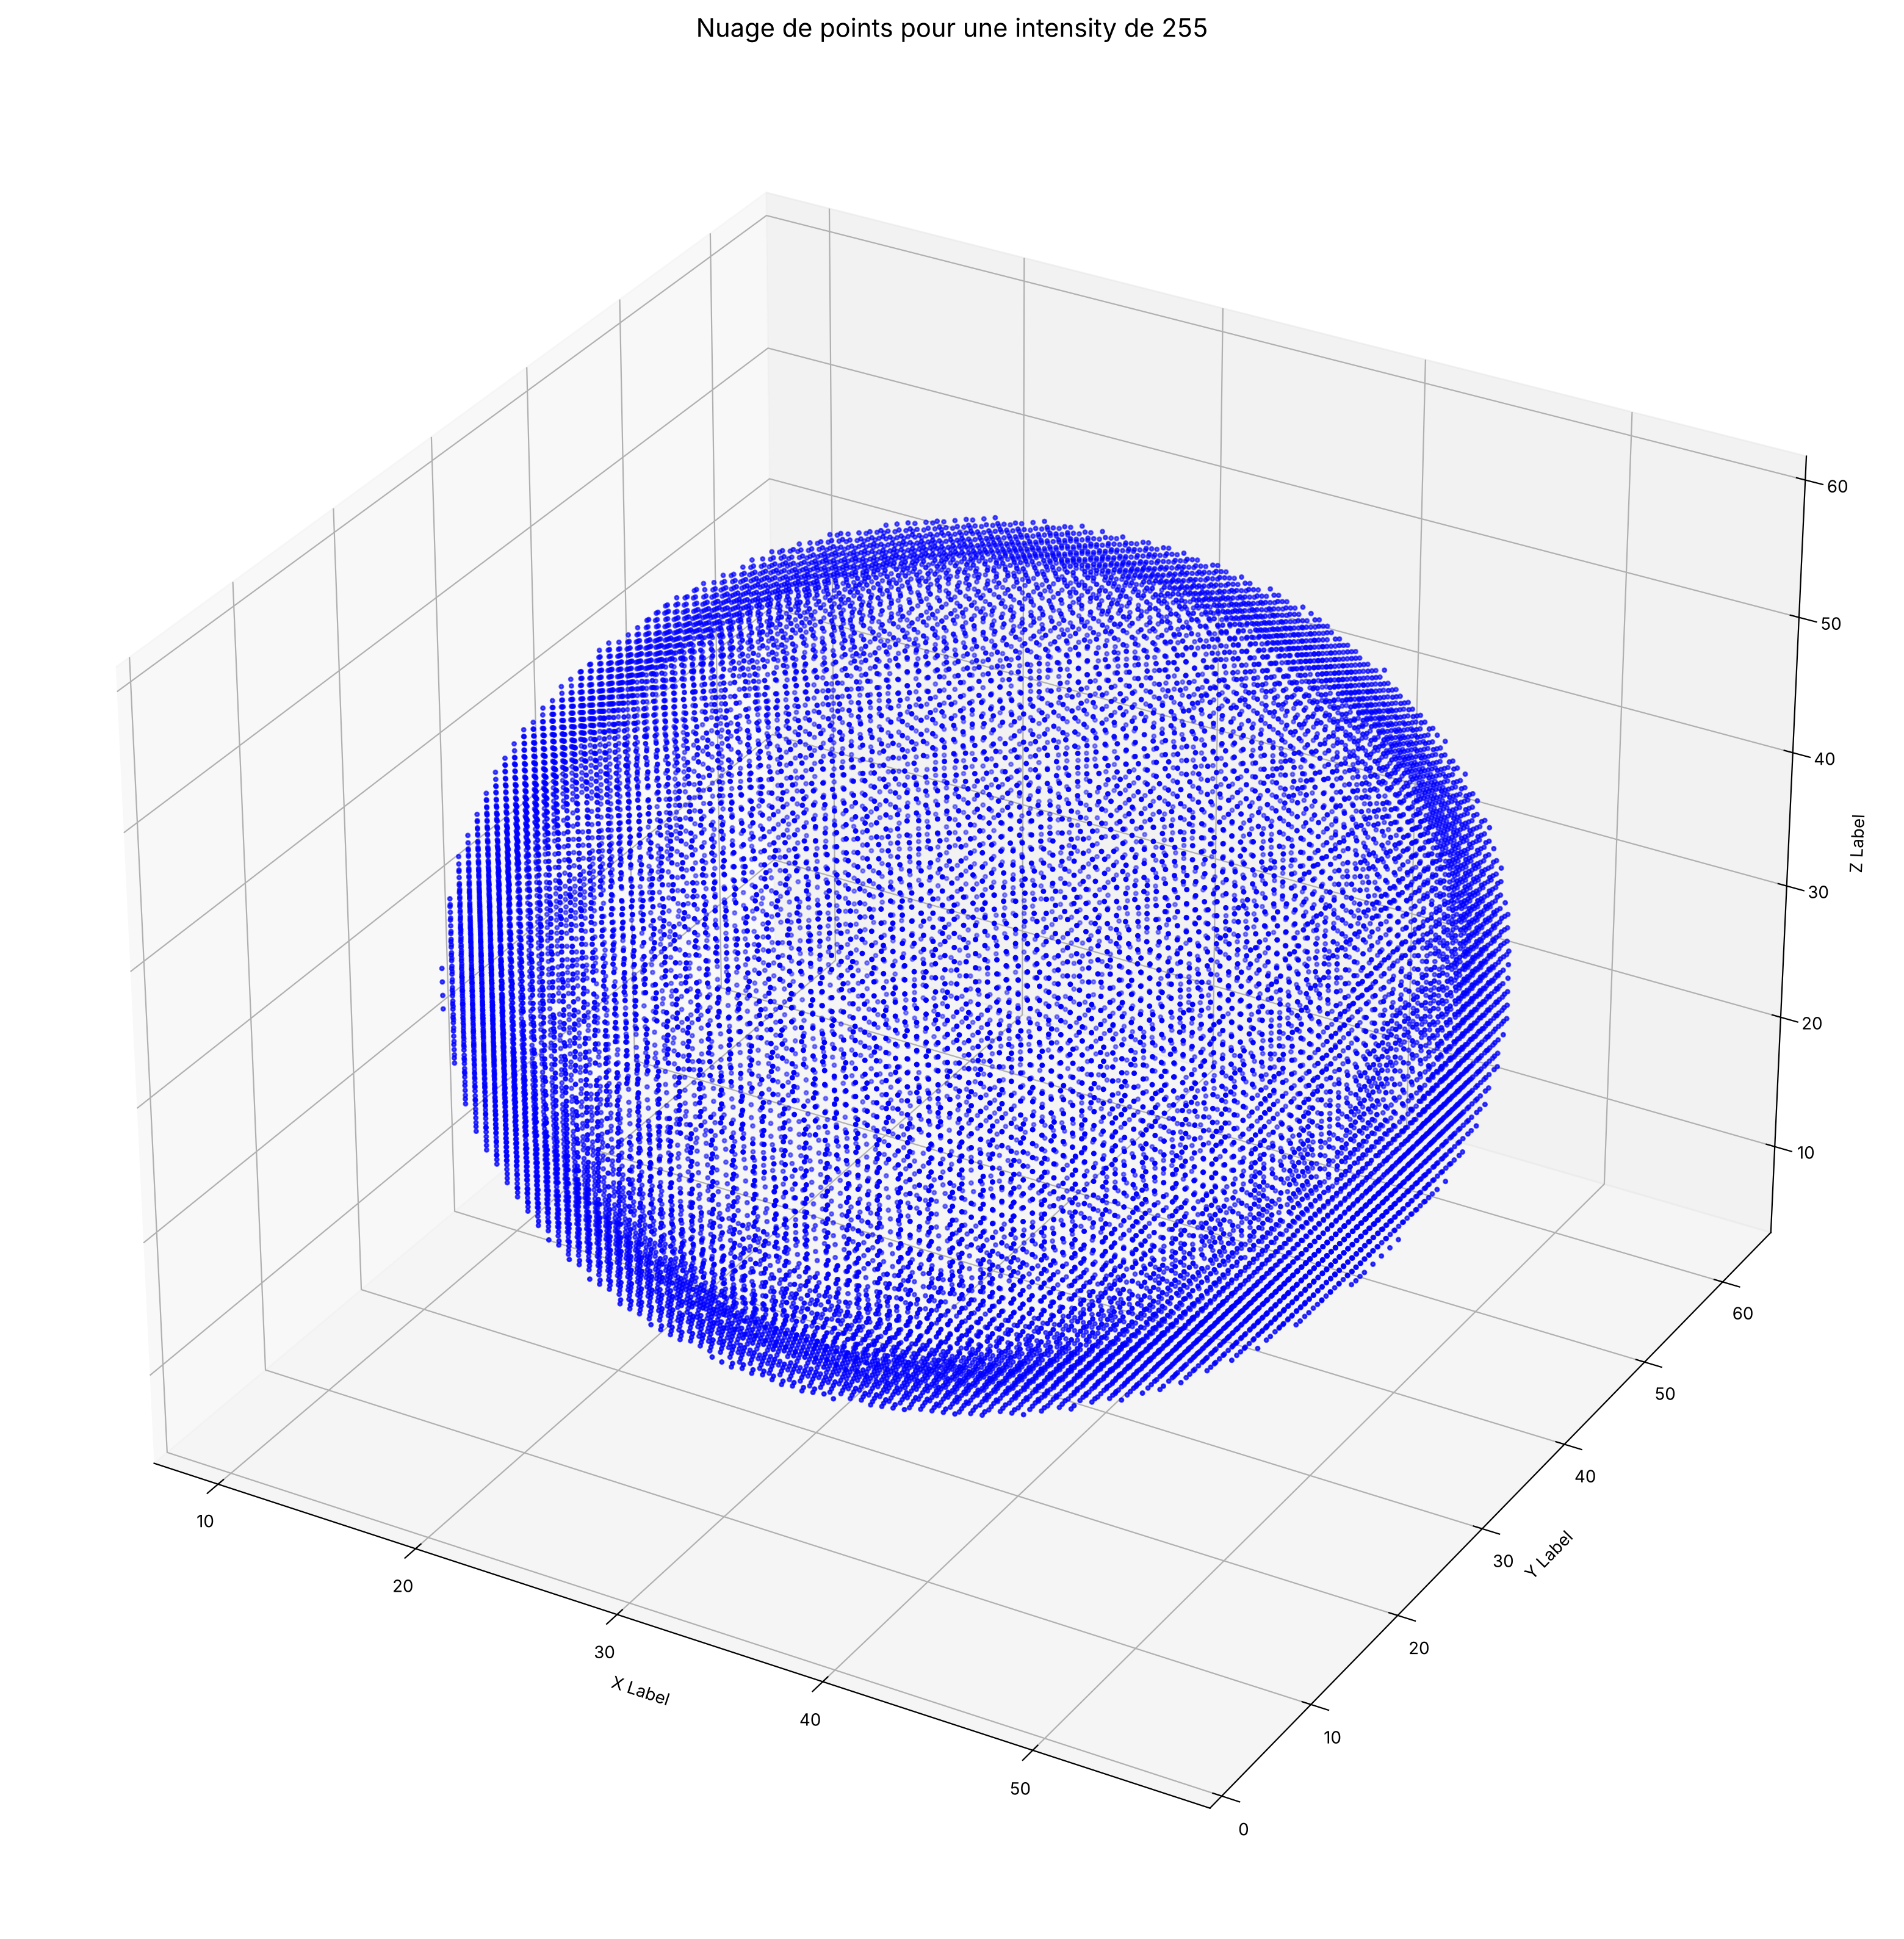

In [4]:
x, y, z= [x for x, y, z in verticeList], [y for x, y, z in verticeList], [z for x, y, z in verticeList]
fig = plt.figure(figsize=(20,20))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z, c='b', marker='.')
ax.set_xlabel('X Label')
ax.set_ylabel('Y Label')
ax.set_zlabel('Z Label')
ax.set_title("Nuage de points pour une intensity de %.i" %label, fontsize=15)
plt.show()



The point cloud of gray level 255 contains the 20 212 vertices of `verticeList`. All the points are on the integer grid, because they are corners of voxels. Together they draw a flattened ellipsoid, which is the shape of the head. As the shell is thin, the points of its outer and inner surfaces are almost on top of each other and the cloud looks like a single dense layer. The rings visible on the cloud are the steps of the staircase: the surface moves by one voxel at a time, so the points are packed in rows. The cloud has no hole at this scale and it is symmetric, as expected for this phantom.

### Combine the point cloud and your surface as a .obj file

- Finally let's create an OBJ file to visualize our surfaces with meshlab (or another software like CloudCompare). OBJ is a very simple file format. It contains an identifier and the list of vertices and of faces in the following syntax :
It's an ASCII file format that can be resumed as such :

    #List of all vertices

    v x1 y1 z1

    v x2 y2 z2

    v x3 y3 z3

    #List of all faces

    f 1 2 3

##### See here that the face list begins with the index 1. So make sure when you create the faceList to use the correct indices


In [ ]:


def write_obj(filename, objects):
    """Write a .obj file. objects is a dictionary {name: (vertices, faces)} and each object is written as a group.
    Face indices start at 1 and count the vertices of the whole file, so after the first object an offset is added."""
    offset = 0
    with open(filename, "w") as f:
        f.write("# Surfaces extracted from shepplogan.pgm3d\n")
        for name, (vertices, faces) in objects.items():
            f.write(f"o {name}\n")
            f.write("#List of all vertices\n")
            for x, y, z in vertices:
                f.write(f"v {x} {y} {z}\n")
            f.write("#List of all faces\n")
            for a, b, c in faces:
                f.write(f"f {a + offset} {b + offset} {c + offset}\n")
            offset += len(vertices)


# first file : the surface of the outer shell (gray level 255), the one displayed above
write_obj("shepplogan_surface_255.obj", {f"gray_level_{label}": (verticeList, faceList)})
# second file : the surfaces of all the objects, each one in its own group
write_obj("shepplogan_all_surfaces.obj", {f"gray_level_{g}": s for g, s in surfaces.items()})
print("shepplogan_surface_255.obj and shepplogan_all_surfaces.obj written")

shepplogan_surface_255.obj and shepplogan_all_surfaces.obj written


shepplogan_surface_255.obj : 20212 vertices, 46912 triangles, face indices from 1 to 20212 | consistent : True


shepplogan_all_surfaces.obj : 37206 vertices, 80928 triangles, face indices from 1 to 37206 | consistent : True


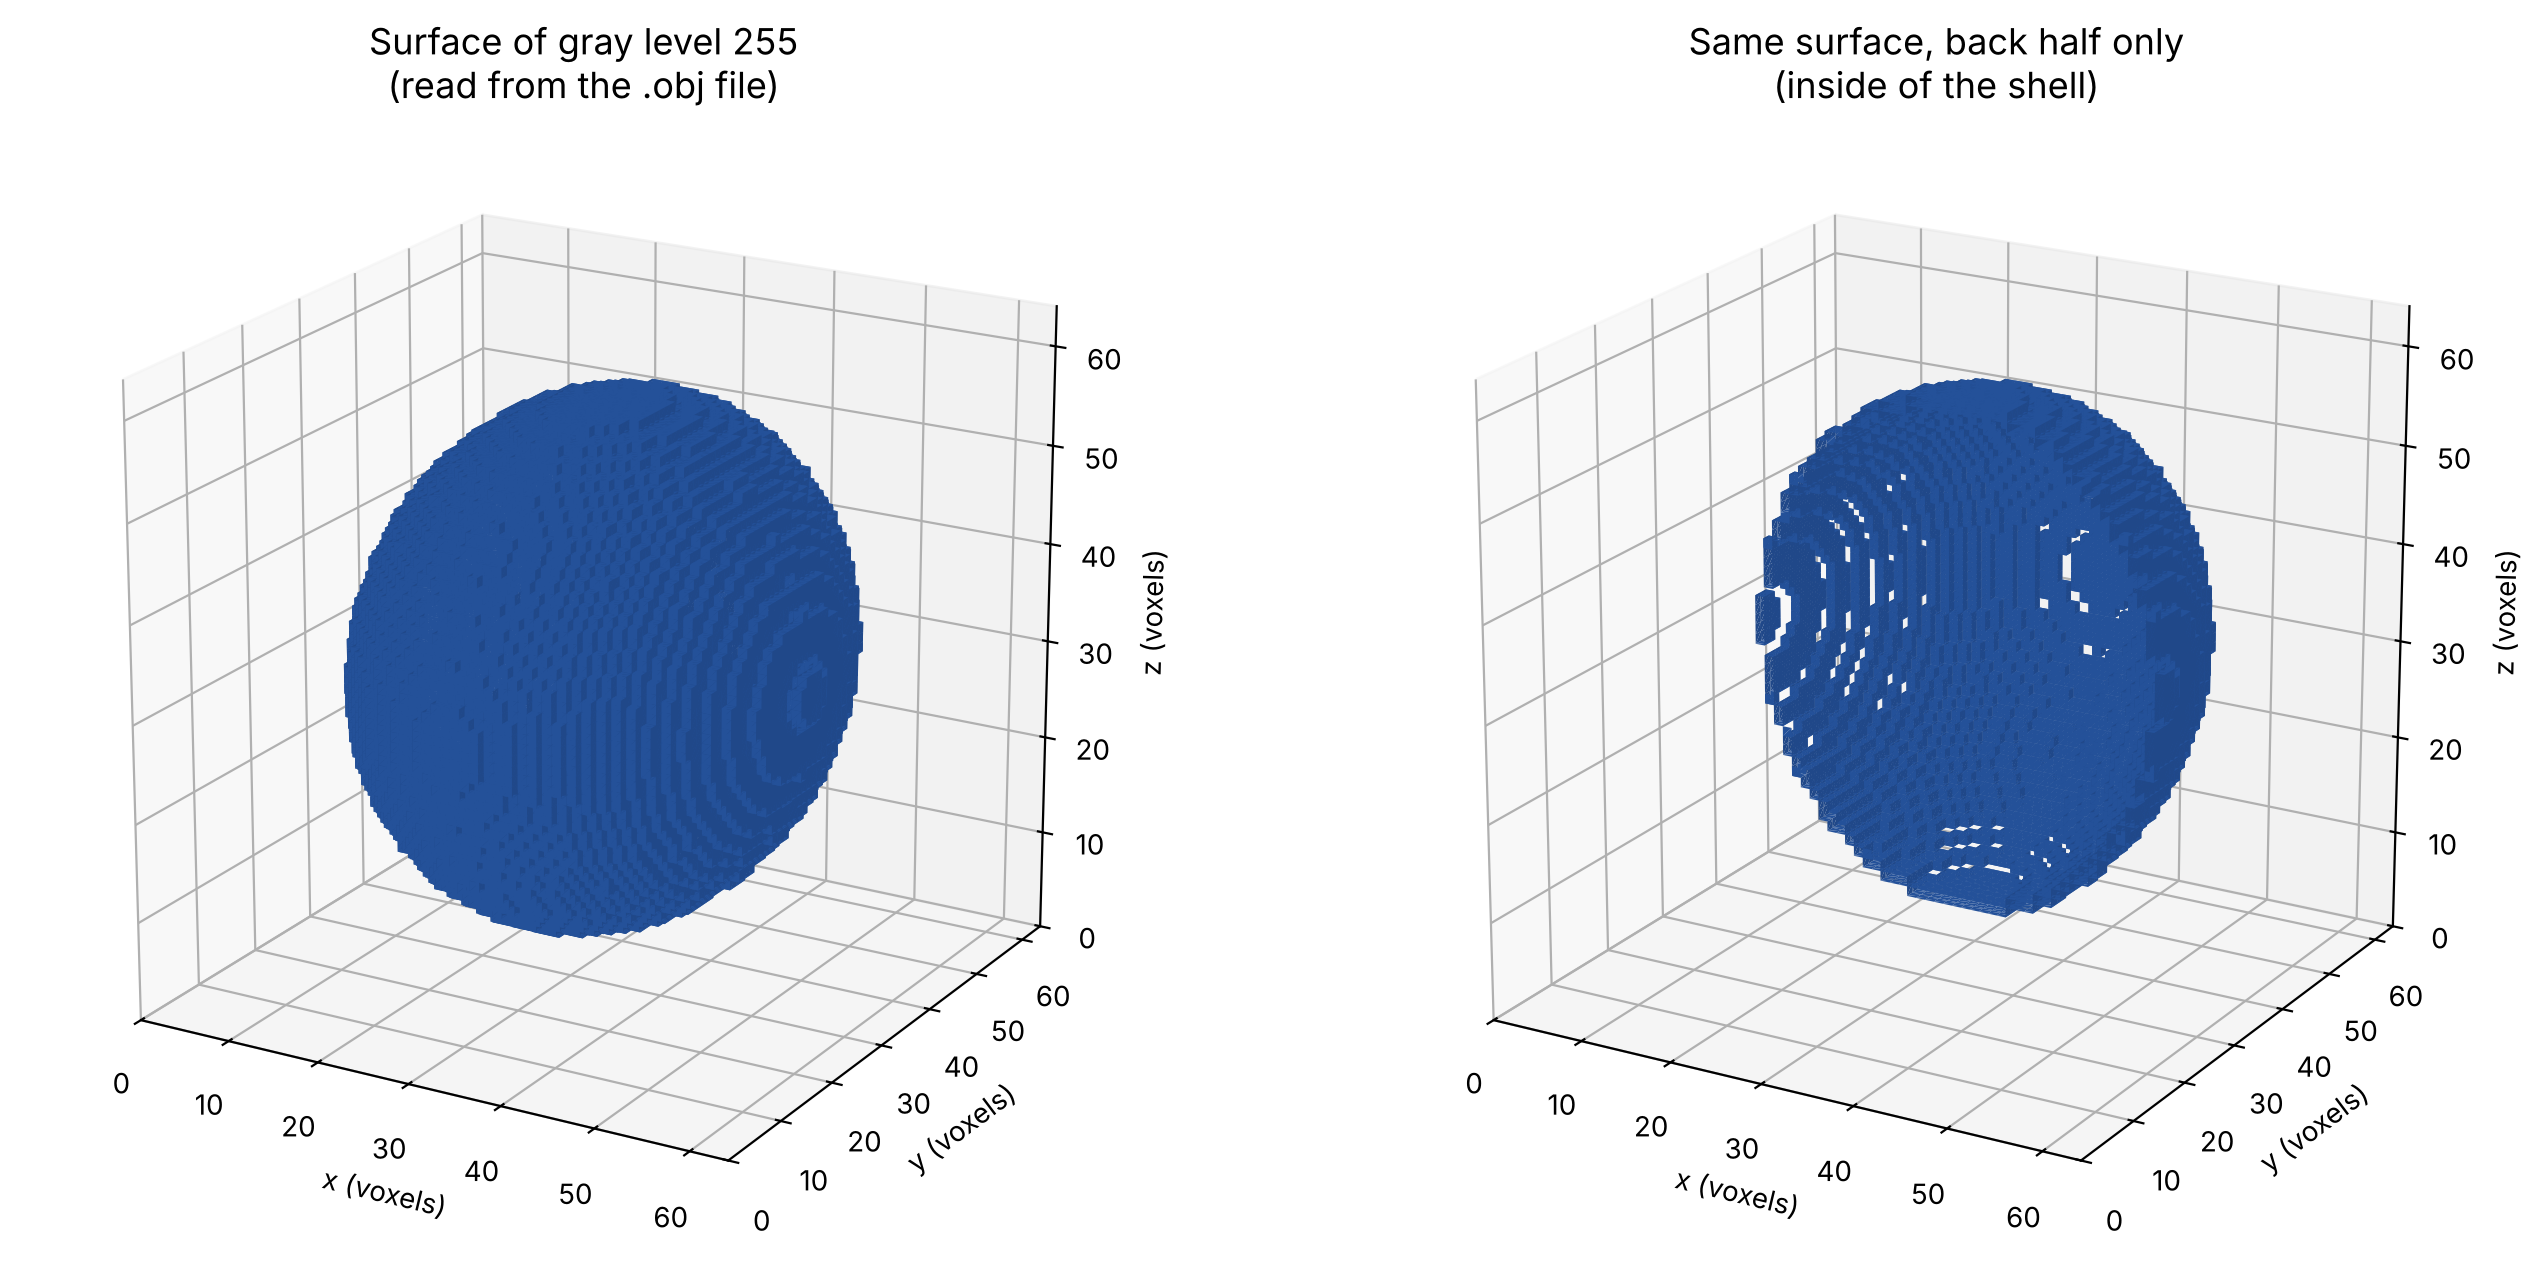

In [ ]:

from mpl_toolkits.mplot3d.art3d import Poly3DCollection


def read_obj(filename):
    """Read the vertices (v lines) and the triangles (f lines) of a .obj file."""
    vertices, faces = [], []
    with open(filename) as f:
        for line in f:
            parts = line.split()
            if not parts or parts[0].startswith("#"):
                continue
            if parts[0] == "v":
                vertices.append([float(p) for p in parts[1:4]])
            elif parts[0] == "f":
                faces.append([int(p) for p in parts[1:4]])
    return np.array(vertices), np.array(faces)


def show_mesh(ax, vertices, faces, title, color=(0.2, 0.45, 0.85), half=False):
    """Display a triangle mesh (faces start at 0). Each triangle is shaded with the direction of its normal.
    With half=True only the back half (y >= middle) is kept, to look at the inside of the volume."""
    triangles = np.asarray(vertices, dtype=float)[np.asarray(faces)]
    if half:
        triangles = triangles[triangles[:, :, 1].mean(axis=1) >= size[1] / 2]
    normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
    normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
    light = np.array([0.5, -0.6, 0.6])
    light /= np.linalg.norm(light)
    shade = 0.25 + 0.75 * np.abs(normals @ light)
    ax.add_collection3d(Poly3DCollection(triangles, facecolors=shade[:, None] * np.array(color), edgecolors="none"))
    ax.set_xlim(0, size[0])
    ax.set_ylim(0, size[1])
    ax.set_zlim(0, size[2])
    ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("x (voxels)")
    ax.set_ylabel("y (voxels)")
    ax.set_zlabel("z (voxels)")
    ax.set_title(title, fontsize=13)
    ax.view_init(elev=20, azim=-60)



for filename in ["shepplogan_surface_255.obj", "shepplogan_all_surfaces.obj"]:
    v, f = read_obj(filename)
    ok = f.min() == 1 and f.max() == len(v)
    print(f"{filename} : {len(v)} vertices, {len(f)} triangles, face indices from {f.min()} to {f.max()} | consistent : {ok}")

v, f = read_obj("shepplogan_surface_255.obj")
fig = plt.figure(figsize=(16, 8))
ax = fig.add_subplot(121, projection="3d")
show_mesh(ax, v, f - 1, "Surface of gray level 255\n(read from the .obj file)")
ax = fig.add_subplot(122, projection="3d")
show_mesh(ax, v, f - 1, "Same surface, back half only\n(inside of the shell)", half=True)
plt.show()



Two .obj files were written with the vertices (`v x y z`) followed by the faces (`f i j k`):
- `shepplogan_surface_255.obj` contains the surface of the outer shell, the one displayed above;
- `shepplogan_all_surfaces.obj` contains the surfaces of the five objects, each one as its own group (`o gray_level_...`). Face indices are counted over the whole file, so an offset is added after each object. Each object is closed by itself, so a face between two objects (for example tissue against shell) appears once for each side, with opposite normals.

To check them, I read the files again with a small reader. The face indices go from 1 to the number of vertices in both files, and the number of vertices and triangles is the same as in the lists. The surface read from the file is displayed with a shading that depends on the normal of each triangle. The files can be opened in MeshLab or CloudCompare.

The view of the back half (right figure) shows the inside of the shell. A few small openings can be seen. They are really in the data: the shell is one voxel thick almost everywhere and brain tissue touches the empty space directly on about 2 400 faces, so the phantom is not completely watertight there. The mesh follows the data exactly, as the volume check above also confirms.

<div style="display: flex; align-items: center;">
    <img src="https://paulbourke.net/geometry/polygonise/polygonise4.gif" alt="Image Alt Text" width="200" height="200" style="margin-right: 20px;">
    <div style="font-size: 30px;">
         <strong> Part 2<strong>
    <div style="font-size: 20px;margin-right: 30px">
         <strong> Marching Cubes Algorithm<strong>
    </div>
</div>

The Marching Cubes algorithm (Marching Square in 2D) is designed to extract 2D surfaces from a 3D (voxels) volume. It relies on the concept of isosurfaces. An isosurface is the surface separating two different material. For instance in the Shepp-Logan phantom, there is an isosurface between the exterior of the phantow (graylevel 0) and its outer shell (graylevel 255). It is often used in medical imaging to visualize a specific structure (for instance bones which are easy to segment in CT scan). 
As we have seen during the course, it uses a lookup table to find the configuration between the neighbors of a voxel to create faces.

An isosurface is a three-dimensional analog of an isoline. It is a surface that represents points of a constant value within a volume of space; in other words, it is a level set of a continuous function whose domain is 3-space. 

For reference :
- marching squares animated : https://jamie-wong.com/2014/08/19/metaballs-and-marching-squares/
- the original paper from Lorensen and Cline : https://citeseerx.ist.psu.edu/doc/10.1.1.132.3930
- A full implementation of the algorithm can be found at https://github.com/alvin-yang68/Marching-Cubes/tree/main
- Check carefully the reference https://paulbourke.net/geometry/polygonise/

### Try the ready-to-use scikit functions

- You have an example of use at https://scikit-image.org/docs/stable/auto_examples/edges/plot_marching_cubes.html 
- Now, you have to use these Scikit functions on the shepplogan.pgm3d phantom to extract its isosurfaces.
- You can either save them in an OBJ file or visualize them directly on the notebook with the functions provided in the example above.

level | vertices | triangles | surface area (voxel units) | enclosed volume
127.5 |    23456 |     47328 |                    17190.2 |          9222.0
   38 |    14796 |     29580 |                    11279.4 |         69021.4
   64 |     1650 |      3280 |                     1192.6 |          2897.2


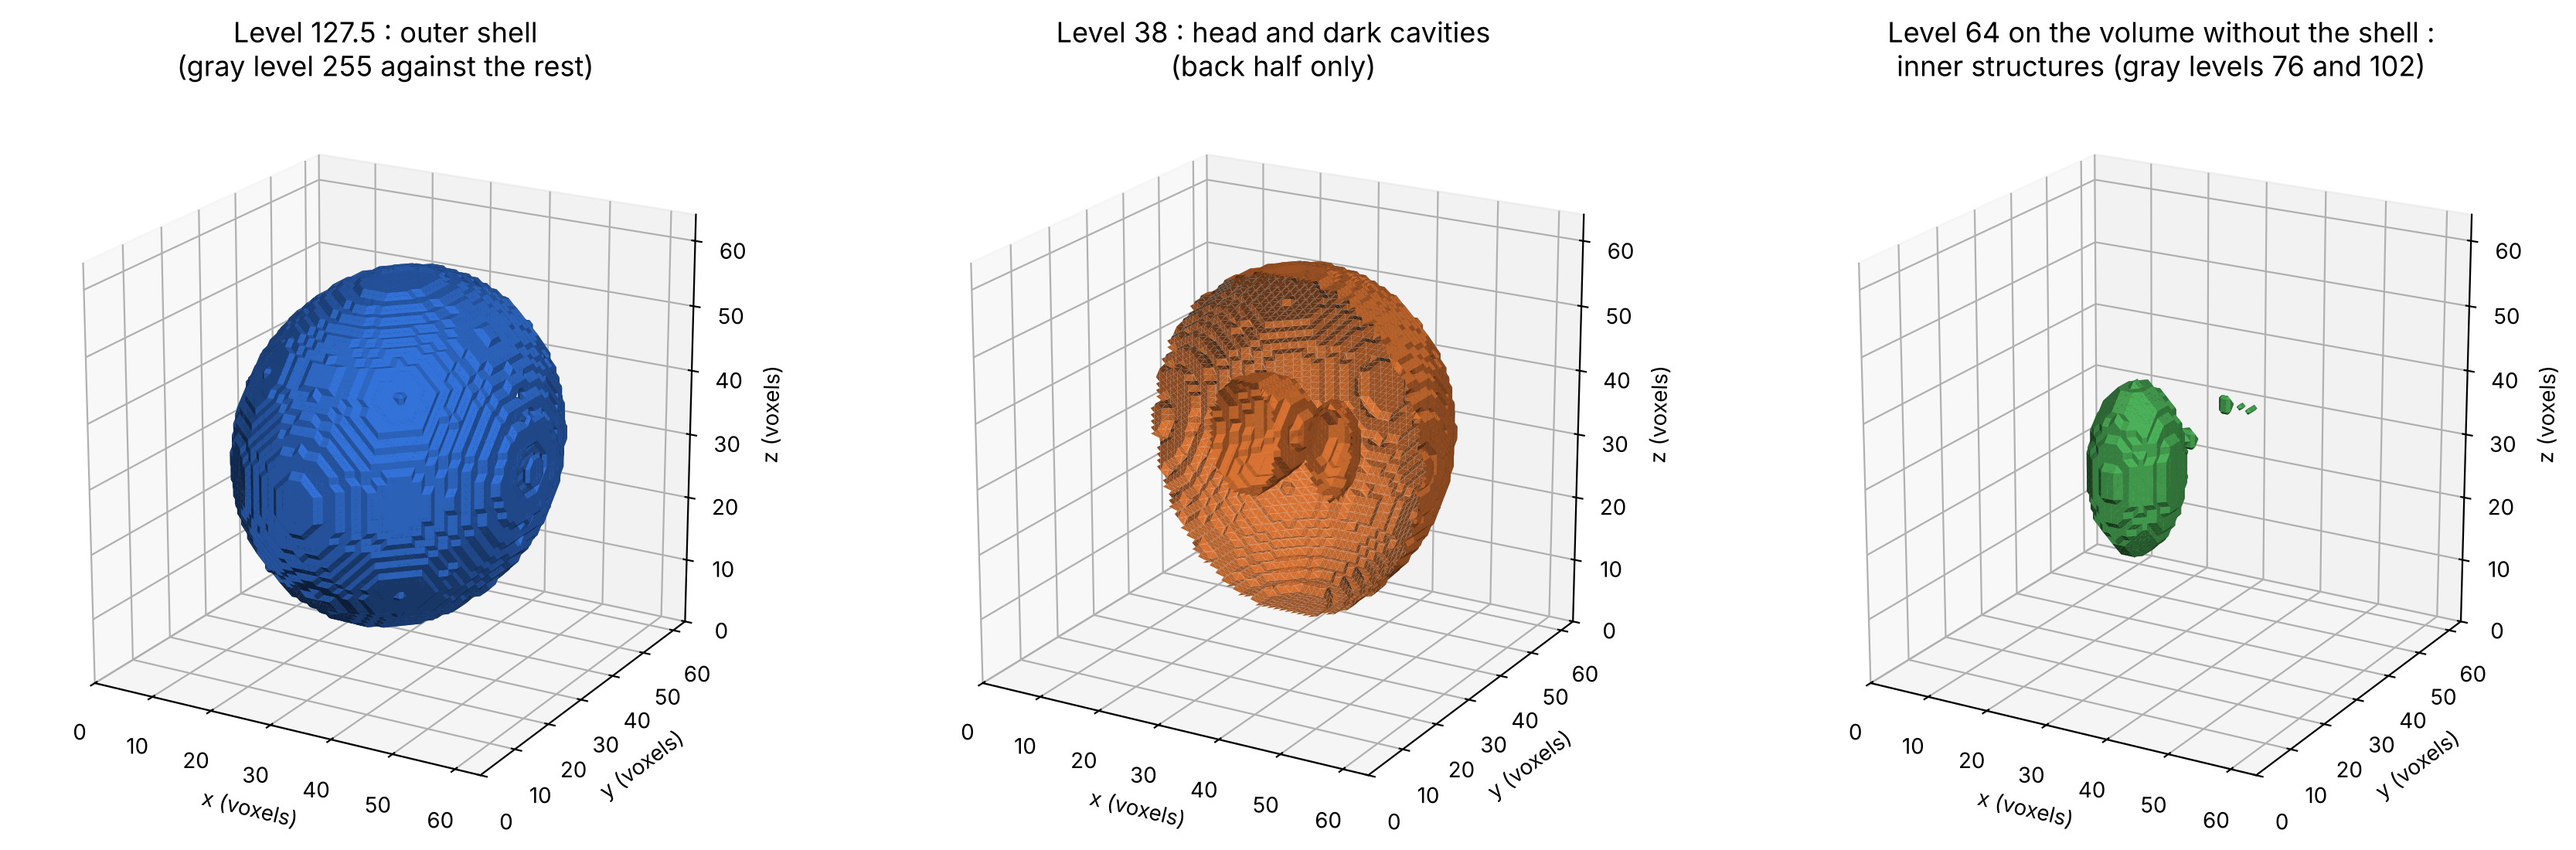


Outer shell :
  faces between voxels (first part) : 20212 vertices, 46912 triangles, area = 23456.0
  marching cubes                    : 23456 vertices, 47328 triangles, area = 17190.2
shepplogan_marching_cubes_shell.obj written : 23456 vertices, 47328 triangles, face indices from 1 to 23456


In [ ]:

from skimage import measure


def marching_cubes_xyz(vol, level):
    """Isosurface of a volume with the marching cubes of scikit-image. Returns vertices (x, y, z) and triangles."""
    verts, faces, normals, values = measure.marching_cubes(vol.astype(float), level=level)
    # skimage gives the vertices in the order of the array axes (z, y, x) : they are put back in the order (x, y, z).
    # +0.5 because skimage places the centre of voxel (x, y, z) at (x, y, z) while the first part works with the
    # corners of the voxels, so the meshes of both parts are in the same coordinates.
    return verts[:, ::-1] + 0.5, faces


# an isosurface at a level is the surface separating the voxels below the level from the voxels above it.
# The levels are chosen between two gray levels of the phantom.
without_shell = np.where(volume == 255, 51, volume)     # shell replaced by the brain intensity, to see what is inside
isosurfaces = [
    ("Level 127.5 : outer shell\n(gray level 255 against the rest)", volume, 127.5, False, (0.2, 0.45, 0.85)),
    ("Level 38 : head and dark cavities\n(back half only)", volume, 38, True, (0.85, 0.45, 0.2)),
    ("Level 64 on the volume without the shell :\ninner structures (gray levels 76 and 102)", without_shell, 64, False, (0.3, 0.7, 0.35)),
]

fig = plt.figure(figsize=(21, 7))
results = {}
print("level | vertices | triangles | surface area (voxel units) | enclosed volume")
for i, (title, vol, level, half, color) in enumerate(isosurfaces):
    verts, faces = marching_cubes_xyz(vol, level)
    area = measure.mesh_surface_area(verts, faces)
    results[level] = (verts, faces)
    print(f"{level:5} | {len(verts):8d} | {len(faces):9d} | {area:26.1f} | {enclosed_volume(verts, faces + 1):15.1f}")
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    show_mesh(ax, verts, faces, title, color=color, half=half)
plt.show()

# comparison with the surface of the first part for the same object (outer shell, gray level 255)
verts, faces = results[127.5]
print("\nOuter shell :")
print(f"  faces between voxels (first part) : {len(verticeList)} vertices, {len(faceList)} triangles, area = {len(faceList) / 2:.1f}")
print(f"  marching cubes                    : {len(verts)} vertices, {len(faces)} triangles, area = {measure.mesh_surface_area(verts, faces):.1f}")

# the marching cubes surface of the shell is also saved as a .obj file (same indices convention : starting at 1)
write_obj("shepplogan_marching_cubes_shell.obj", {"marching_cubes_level_127.5": (verts, faces + 1)})
v, f = read_obj("shepplogan_marching_cubes_shell.obj")
print(f"shepplogan_marching_cubes_shell.obj written : {len(v)} vertices, {len(f)} triangles, face indices from {f.min()} to {f.max()}")



**Method.** Marching cubes looks at 8 neighbouring voxels (the corners of a cube) and compares each value with a chosen level. The 8 results (above or below the level) give a number from 0 to 255 that selects the triangles to create from a lookup table. The vertices are put on the edges of the cube where the level is crossed, at a position found by linear interpolation of the two values. I used `measure.marching_cubes` with levels chosen between two gray levels, and the isosurface separates the voxels below the level from the voxels above it:
- level 127.5 keeps only the gray level 255, so it gives the outer shell;
- level 38 separates the empty space (0 and 25) from the tissue, so it gives the outside of the head and the surface of the dark cavities (the figure shows the back half to look inside);
- level 64 applied on the volume where the shell was replaced by the tissue value (51) shows the inner structures of gray levels 76 and 102: the large lighter ellipsoid and a few small pieces.

The enclosed volume is positive for the three surfaces, so the normals point outwards (the vertices are put back in the order x, y, z, which keeps the orientation).

**Comparison with the first part (outer shell).**

| | faces between voxels | marching cubes (level 127.5) |
|---|---|---|
| vertices | 20 212 | 23 456 |
| triangles | 46 912 | 47 328 |
| surface area | 23 456 | 17 190 |
| enclosed volume | 8 523 (number of voxels) | 9 222 |

The number of triangles is almost the same, but the aspect is very different. The first method only creates faces parallel to the axes, so the surface is a staircase, and its area is about 1.36 times larger than the area of the smooth surface of marching cubes. The staircase overestimates the area because it goes along the voxel edges instead of the real shape. Marching cubes gives a smoother surface with slanted triangles, which is closer to the real shape. The number of vertices of marching cubes (23 456) is equal to the number of squares of the first method: it creates one vertex on every edge joining a voxel above the level to a voxel below it, and this is exactly one for every shared face. The enclosed volume is a little bigger than the number of voxels because the interpolated surface does not pass exactly on the voxel faces. The file `shepplogan_marching_cubes_shell.obj` contains the marching cubes surface of the shell.